# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 22: Análise de Complementaridade, Efeito Oráculo e Grau de Consenso na CNN 2D — Classe LARGE

**Autor:** Evandro Rocha (UFRJ / COPPE / PEE)
**Data:** Outubro de 2026

---

## Resumo Executivo

A classe **`LARGE`** (embarcações de grande porte, comprimento ≥ 100 m (mercantes, graneleiros, petroleiros)) é analisada nas **2.140 instâncias de teste** acumuladas nos 10 folds do 5×2cv oficial (as mesmas **572 gravações** aparecem, em média, 3,74 vezes no teste; não são 2.140 áudios distintos), com a CNN 2D em 4 representações (**MEL, LOFAR, HHT e DEMON**).

> **Aviso principal — três das quatro CNNs colapsaram.** A CNN MEL foi treinada pelo pipeline `iara`, mas **não tem a arquitetura do artigo** (`test_scripts/cnn.py`: conv 128/64, ReLU, lr 1e-5, imagens sem sobreposição — não é a arquitetura do artigo; SP 63,80 ± 2,23%; CNN MEL do artigo: 63,52%). As CNNs LOFAR, HHT e DEMON são uma **CNN ad hoc** (`scratch/generate_cnn_predictions_and_analysis.py`) treinada sobre caches com média em 5,12 s: **LOFAR** SP 35,40 ± 12,38% (7/10 folds com recall < 10% em alguma classe); **HHT** SP 36,50 ± 4,88% (5/10 folds com recall < 10% em alguma classe); **DEMON** SP 34,62 ± 12,37% (6/10 folds com recall < 10% em alguma classe). A CNN LOFAR do artigo tem SP **66,05 ± 1,90%** (Tabela 7). Com modelos assim, a "complementaridade" abaixo mede sobretudo a **instabilidade** desses modelos (em cada fold eles favorecem uma classe diferente), e **não diz nada sobre a informação contida nas representações** LOFAR, HHT e DEMON.

### Principais resultados (recalculados)
1. **Oráculo não é um sistema realizável.** O oráculo (acerta se ao menos uma CNN acerta) chega a **91,26%** (1.953 / 2.140), mas o esperado se os erros fossem independentes seria **95,57%**: os erros são **correlacionados**, e não ortogonais. O **voto real** das 4 CNNs (pluralidade, empate sorteado) tem recall de `LARGE` de **62,90%**, contra 64,58% da melhor CNN isolada (MEL; F-test 5×2cv sobre o recall, p = 0,503). Em SP global, o voto fica em **55,33 ± 3,07%**, abaixo da CNN MEL isolada (63,80%; p = 0,028, diferença significativa).
2. **Unanimidade:** só **148** instâncias (6,92%) são acertadas pelas 4 CNNs, e **187** (8,74%) são erradas por todas. A baixa unanimidade é o esperado quando três modelos estão perto do acaso; ela não indica "especialização" de filtros.
3. **Resgates exclusivos:** 490 instâncias (22,90%) são acertadas por uma única CNN (líder: **MEL**, 155). Elas correspondem a 255 gravações, das quais só **22** são resgate exclusivo em **todas** as suas aparições no teste: os resgates são instáveis entre folds.

In [1]:
# 1. Configuração do Ambiente e Imports
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

sys.path.insert(0, os.path.abspath('.'))
sys.path.insert(0, os.path.abspath('notebooks'))
sys.path.insert(0, os.path.abspath('src'))  # módulos movidos para notebooks/src
sys.path.insert(0, os.path.abspath('notebooks/src'))
import iara_results as R
import cnn_complementaridade_comum as C

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 15,
    'figure.dpi': 150
})
print("Ambiente configurado. Resultados lidos de", R.ROOT)

Ambiente configurado. Resultados lidos de /workspace/IARA


## 2. Metodologia e Diagnóstico dos Modelos

- **Experimentos** (predições por janela/imagem em disco, agregadas por arquivo com voto majoritário):
  - **MEL** — `cnn` (pipeline iara, `results/trainings/tests/`, `test_scripts/cnn.py` (128/64, lr 1e-5 — não é a arquitetura do artigo))
  - **LOFAR** — `cnn2d_lofar5s_w32_b64_e15_4c` (CNN ad hoc, `results/trainings/multirep/`)
  - **HHT** — `cnn2d_hht_w32_b64_e20_4c` (CNN ad hoc, `results/trainings/multirep/`)
  - **DEMON** — `cnn2d_demon_w32_b64_e20_4c` (CNN ad hoc, `results/trainings/multirep/`)
- **Protocolo:** 5×2cv oficial (10 folds); a partição é por **gravação** (`exclusive_header='ID'`). O mesmo navio pode aparecer em treino e teste.
- **Unidade de contagem:** "instância" = (fold, gravação de teste). Os 2.140 casos de `LARGE` vêm de 572 gravações distintas.
- **ACC** = acurácia balanceada (média dos recalls).

### 2.1 Por que as CNNs ad hoc colapsaram
- Cada imagem da CNN ad hoc tem 32 frames de 5,12 s, ou seja, **≈ 164 s de áudio**, com passo de 16 frames. No cache LOFAR, **18,3%** das gravações têm menos de 32 frames e viram uma única imagem completada por *wrap padding*; 13,7% geram uma imagem sem padding; 68,0% geram 2 imagens (o máximo, já que nenhuma gravação passa de 58 frames). Nos testes, 31,7% dos arquivos têm 1 imagem e o restante, 2. Isso dá ≈ 1.436 imagens de treino no fold 0 (853 gravações), para uma CNN treinada do zero, por 15 épocas fixas, sem validação nem *early stopping*.
- Em cada fold o modelo tende a "escolher" uma classe: o recall de `LARGE` da CNN LOFAR varia de 2,8% a 50,9% entre folds; o da HHT, de 5,1% a 85,5%; o da DEMON, de 42,5% a 89,7%. A CNN MEL do repositório fica entre 58,9% e 70,6%.
- **Sensibilidade ao desempate:** com 2 imagens por arquivo os empates são frequentes. Este notebook usa a regra do pipeline `iara` (`Counter.most_common`: empate → classe da primeira imagem). O script de scratch usa `argmax(bincount)` (empate → menor índice de classe, ou seja, favorece `SMALL`). Trocando a regra: LOFAR: SP 35,40% → 36,23%, recall `LARGE` 27,48% → 27,10%; HHT: SP 36,50% → 39,59%, recall `LARGE` 51,59% → 51,87%; DEMON: SP 34,62% → 37,05%, recall `LARGE` 59,25% → 53,18%. Uma métrica que muda tanto com a regra de desempate não é estável o suficiente para sustentar conclusões sobre as representações.

In [2]:
# 2.1 Diagnóstico: métricas globais e faixa (mín–máx) por fold de cada CNN
display(C.collapse_table())
tb = pd.DataFrame({r: {'SP (iara: empate -> 1ª imagem)': R.summary(e)['SP'][0],
                       'SP (script: empate -> menor índice)': C.sp_lowest_index_tiebreak(e)['SP'].mean(),
                       'R_SMALL (iara)': R.summary(e)['R_SMALL'][0],
                       'R_SMALL (script)': C.sp_lowest_index_tiebreak(e)['R_SMALL'].mean()}
                   for r, e in C.CNN.items() if r != 'MEL'}).T
display(tb.round(2))
print('Imagens por arquivo de teste (CNN LOFAR ad hoc):', C.images_per_file().value_counts().sort_index().to_dict())
print('CNN do artigo (Tabela 7):', {k: v['SP'] for k, v in R.ARTICLE_TABLE7.items() if k[0] == 'CNN'})

,Experimento,SP,ACC (bal.),SP mín–máx,SMALL mín–máx,MEDIUM mín–máx,LARGE mín–máx,BACKGROUND mín–máx,folds c/ recall < 10% em alguma classe
Representação,,,,,,,,,
MEL,cnn,63.80 ± 2.23,65.01 ± 2.05,59.8–67.2,34.8–46.6,59.7–70.5,58.9–70.6,82.7–91.8,0
LOFAR,cnn2d_lofar5s_w32_b64_e15_4c,35.40 ± 12.38,47.58 ± 2.43,0.0–45.6,5.1–82.6,0.0–83.2,2.8–50.9,74.5–99.0,7
HHT,cnn2d_hht_w32_b64_e20_4c,36.50 ± 4.88,41.91 ± 3.54,26.6–42.6,4.5–28.1,3.4–65.1,5.1–85.5,56.1–81.6,5
DEMON,cnn2d_demon_w32_b64_e20_4c,34.62 ± 12.37,43.43 ± 3.78,0.0–45.0,0.0–28.7,16.1–76.5,42.5–89.7,26.5–94.9,6


,SP (iara: empate -> 1ª imagem),SP (script: empate -> menor índice),R_SMALL (iara),R_SMALL (script)
LOFAR,35.40,36.23,39.21,45.90
HHT,36.50,39.59,14.33,19.78
DEMON,34.62,37.05,10.62,15.17


Imagens por arquivo de teste (CNN LOFAR ad hoc): {1: 2024, 2: 4366}
CNN do artigo (Tabela 7): {('CNN', 'MEL'): (63.52, 2.26), ('CNN', 'LOFAR'): (66.05, 1.9)}


In [3]:
# 2.2 Análise da classe LARGE: tabelas recalculadas das predições em disco
CLASSE = 2
A = C.analyze(C.CNN, CLASSE)
df_hits, df_consensus, df_exclusive, df_reverse, df_confusion_pattern = C.tables(A, CLASSE)
total = A['n']
print(f"{total} instâncias de teste de LARGE ({A['n_files']} gravações distintas)")
display(df_hits.round(2))
display(df_consensus.round(2))
display(df_reverse.round(2))

2140 instâncias de teste de LARGE (572 gravações distintas)


,Representacao,Acertos,Recall_Pct
0,LOFAR,588.0,27.48
1,HHT,1104.0,51.59
2,DEMON,1268.0,59.25
3,MEL,1382.0,64.58
4,ORÁCULO CNN (≥1/4; não realizável),1953.0,91.26
5,Esperado c/ erros independentes,NaN,95.57
6,Voto real (pluralidade),NaN,62.90


,Nivel_Consenso,Instancias,Pct_Total,Pct_Dentro_Oraculo
0,4 de 4 (Unanimidade),148,6.92,7.58
1,3 de 4 (Alto Consenso),630,29.44,32.26
2,2 de 4 (Dividido),685,32.01,35.07
3,1 de 4 (Resgate Exclusivo),490,22.90,25.09
4,0 de 4 (Erro Comum),187,8.74,NaN


,Destino_Troca,Mantem_do_MEL,Perde_do_MEL (Efeito Reverso),Pct_Perda_Acertos (%),Resgata_Erros_MEL,Pct_Resgate_Erros (%),Saldo_Liquido
0,Para LOFAR,408,974,70.48,180,23.75,-794
1,Para HHT,794,588,42.55,310,40.90,-278
2,Para DEMON,909,473,34.23,359,47.36,-114


## 3. Efeito Oráculo: Recall Isolado, Teto Teórico e Voto Real

- Recall isolado em `LARGE`: MEL 64,58%, DEMON 59,25%, HHT 51,59%, LOFAR 27,48%.
- **Oráculo (≥ 1/4): 91,26%** (1.953 instâncias). O oráculo usa o rótulo verdadeiro para escolher o modelo e **não é um sistema realizável**: é só um limite superior.
- **Esperado com erros independentes:** 95,57% (1 − ∏(1 − rᵢ), média por fold). O oráculo observado fica 4,31 p.p. abaixo: os erros das CNNs são correlacionados.
- Mesmo quatro preditores ao acaso dariam um oráculo alto (com 4 classes, ≈ 1 − 0,75⁴ ≈ 68%). Por isso o "ganho do oráculo" sobre o melhor modelo isolado (26,68 p.p. sobre MEL) não mede complementaridade útil.
- **Voto real** (pluralidade, empate sorteado): recall de `LARGE` = **62,90%** (p = 0,503 contra MEL).

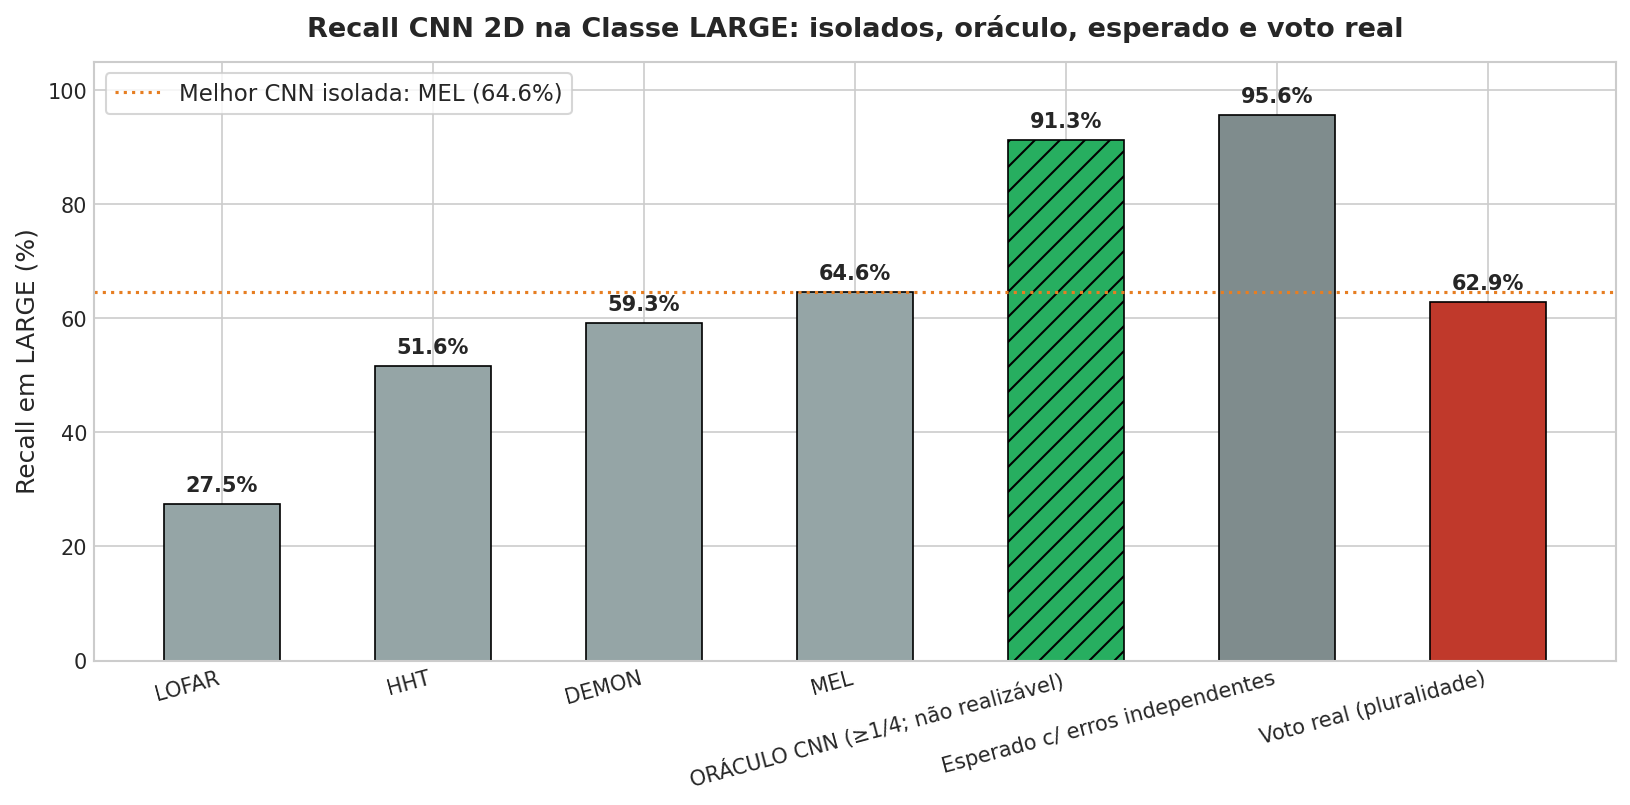

In [4]:
# 3. Gráfico: recall isolado vs. oráculo, esperado sob independência e voto real
plt.figure(figsize=(11, 5.5))
colors = ['#95a5a6'] * (len(df_hits) - 3) + ['#27ae60', '#7f8c8d', '#c0392b']
bars = plt.bar(df_hits['Representacao'], df_hits['Recall_Pct'], color=colors, width=0.55, edgecolor='black', linewidth=0.8)
bars[-3].set_hatch('//')
plt.axhline(A['recall'][A['base']], color='#e67e22', linestyle=':', lw=1.5, label=f"Melhor CNN isolada: {A['base']} ({A['recall'][A['base']]:.1f}%)")
plt.title('Recall CNN 2D na Classe LARGE: isolados, oráculo, esperado e voto real', fontweight='bold', pad=12)
plt.ylabel('Recall em LARGE (%)')
plt.ylim(0, 105)
plt.xticks(rotation=15, ha='right')
for bar in bars:
    h = bar.get_height()
    plt.annotate(f'{h:.1f}%', xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 4), textcoords="offset points",
                 ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

## 4. Grau de Consenso

- **4/4 certas (unanimidade):** 148 (6,92%);
- **3/4:** 630 (29,44%);
- **2/4:** 685 (32,01%);
- **1/4 (resgate exclusivo):** 490 (22,90%);
- **0/4 (erro comum):** 187 (8,74%).

### Regras de votação
- **Unanimidade (4/4):** 6,92%;
- **Maioria estrita (≥ 3/4):** 36,36% (778);
- **"≥ 2/4":** 68,36% (1.463). Essa contagem trata empates 2×2 como acerto, então é um oráculo parcial, não um voto;
- **Voto real (pluralidade, empate sorteado):** 62,90%;
- **Oráculo (≥ 1/4):** 91,26%.

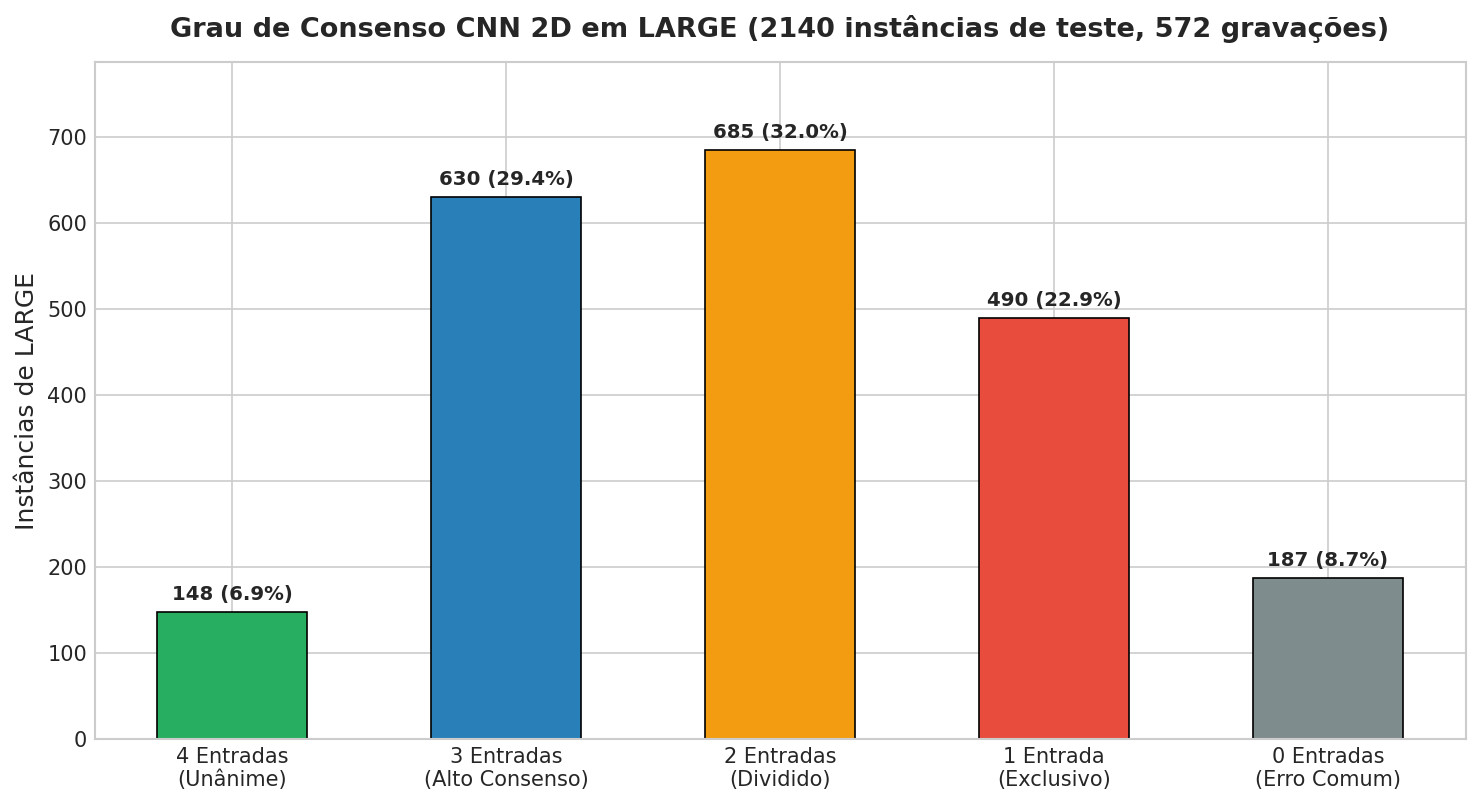

In [5]:
# 4. Visualização do grau de consenso
plt.figure(figsize=(10, 5.5))
labels_cons = ['4 Entradas\n(Unânime)', '3 Entradas\n(Alto Consenso)', '2 Entradas\n(Dividido)', '1 Entrada\n(Exclusivo)', '0 Entradas\n(Erro Comum)']
counts_cons = df_consensus['Instancias'].values
pcts_cons = df_consensus['Pct_Total'].values
bars = plt.bar(labels_cons, counts_cons, color=['#27ae60', '#2980b9', '#f39c12', '#e74c3c', '#7f8c8d'], edgecolor='black', linewidth=0.8, width=0.55)
plt.title(f'Grau de Consenso CNN 2D em LARGE ({total} instâncias de teste, {A["n_files"]} gravações)', fontweight='bold', pad=12)
plt.ylabel('Instâncias de LARGE')
plt.ylim(0, max(counts_cons) * 1.15)
for bar, pct in zip(bars, pcts_cons):
    h = bar.get_height()
    plt.annotate(f'{int(h)} ({pct:.1f}%)', xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 4), textcoords="offset points",
                 ha='center', va='bottom', fontsize=9.5, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Resgates Exclusivos e Padrão de Erro

### Resgates exclusivos em `LARGE` (apenas uma CNN acerta)
- **MEL:** 155 instâncias (7,24%)
- **DEMON:** 153 instâncias (7,15%)
- **HHT:** 113 instâncias (5,28%)
- **LOFAR:** 69 instâncias (3,22%)

No total são 490 instâncias, de 255 gravações. Só **22** gravações são resgate exclusivo em todas as suas aparições no teste; as demais dependem do fold. Nas CNNs colapsadas, um "resgate exclusivo" costuma ser apenas o fold em que o modelo passou a favorecer `LARGE`. Explicações mecânicas (raias espectrais, modulação de pás etc.) para esses resgates **não têm suporte** nestes dados e foram retiradas.

### Para onde vão os erros (percentual dos erros de cada CNN)
| Entrada | Erros | SMALL | MEDIUM | BACKGROUND |
| :--- | ---: | :---: | :---: | :---: |
| **MEL** | 758 | 37,07% | 54,62% | 8,31% |
| **LOFAR** | 1552 | 39,56% | 41,24% | 19,20% |
| **HHT** | 1036 | 18,82% | 42,66% | 38,51% |
| **DEMON** | 872 | 19,95% | 52,06% | 27,98% |

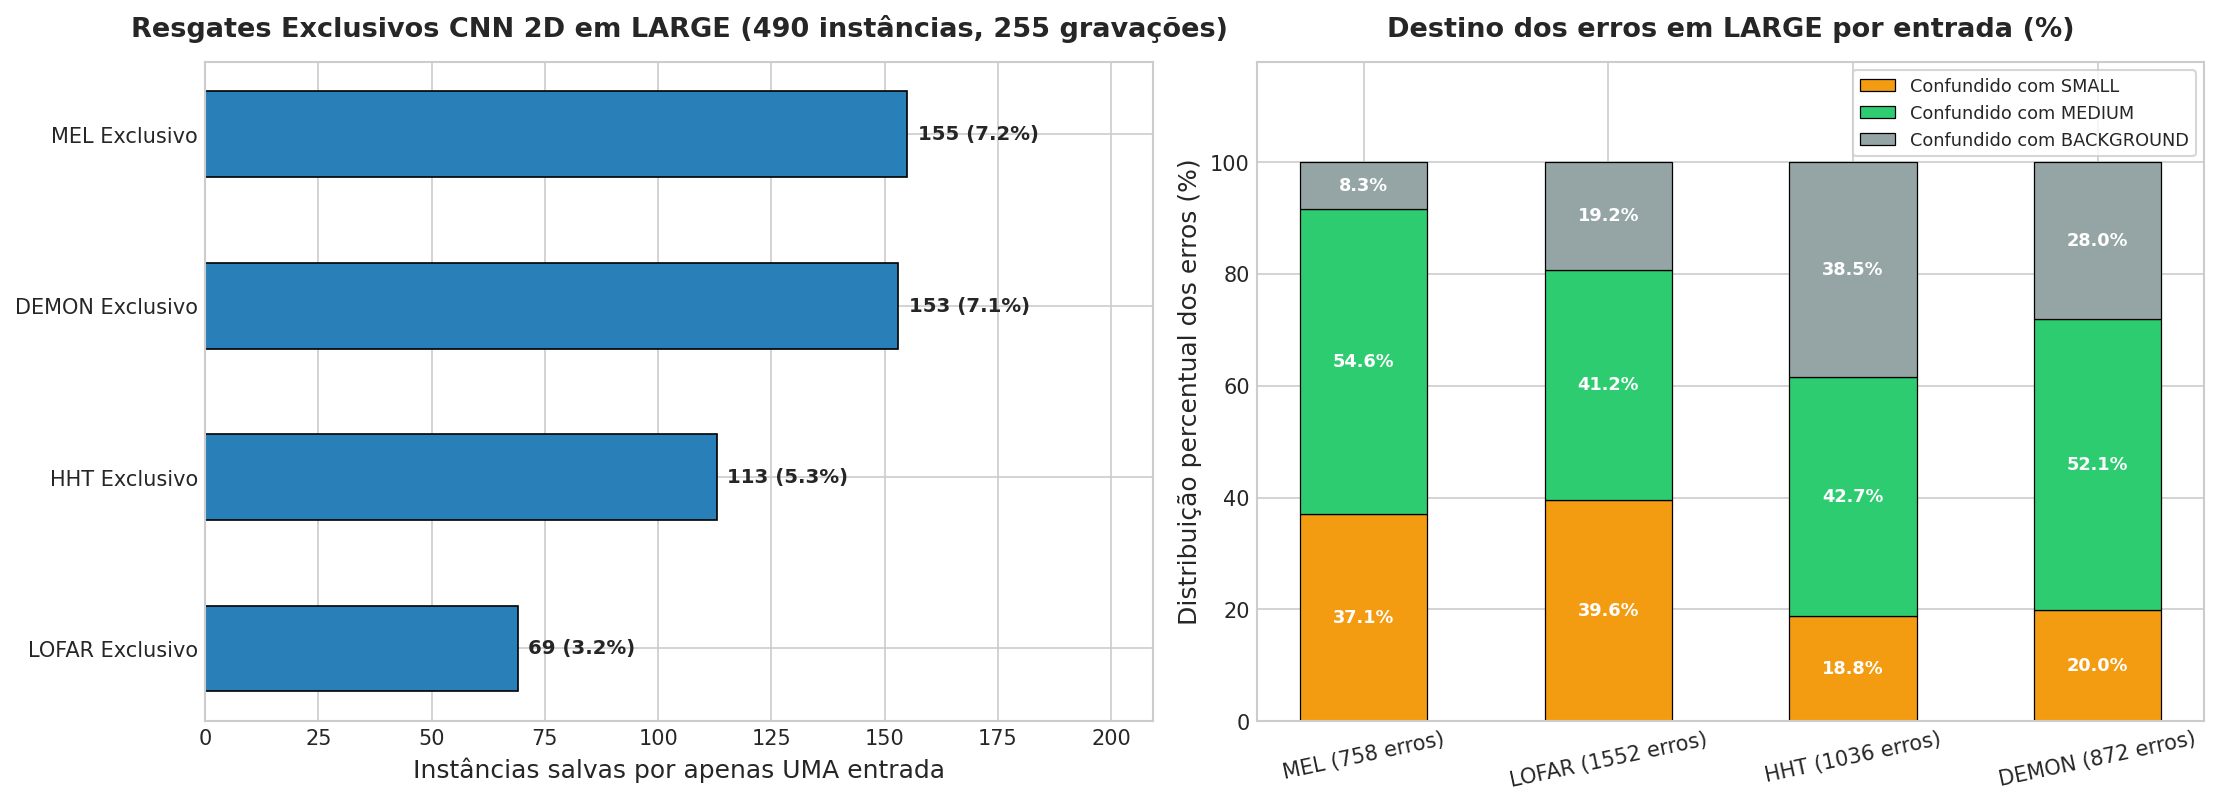

In [6]:
# 5. Resgates exclusivos e padrão de confusão
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
bars_excl = ax1.barh(df_exclusive['Representacao'], df_exclusive['Instancias_Salvas'], color='#2980b9', height=0.5, edgecolor='black', linewidth=0.8)
ax1.set_title(f'Resgates Exclusivos CNN 2D em LARGE ({int(df_exclusive.Instancias_Salvas.sum())} instâncias, {A["exclusive_files"]} gravações)', fontweight='bold', pad=12)
ax1.set_xlabel('Instâncias salvas por apenas UMA entrada')
ax1.set_xlim(0, df_exclusive['Instancias_Salvas'].max() * 1.35)
for bar, pct in zip(bars_excl, df_exclusive['Percentual']):
    w = bar.get_width()
    ax1.annotate(f'{int(w)} ({pct:.1f}%)', xy=(w, bar.get_y() + bar.get_height()/2), xytext=(5, 0), textcoords="offset points",
                 ha='left', va='center', fontsize=9.5, fontweight='bold')

reps = df_confusion_pattern['Representacao']
cols = [c for c in df_confusion_pattern.columns if c.startswith('Confundido_')]
bottom = np.zeros(len(reps))
for col, color in zip(cols, ['#f39c12', '#2ecc71', '#95a5a6']):
    vals = df_confusion_pattern[col].values
    ax2.bar(reps, vals, 0.52, bottom=bottom, label=col.replace('Confundido_', 'Confundido com ').replace('_Pct', ''), color=color, edgecolor='black', linewidth=0.6)
    for i, v in enumerate(vals):
        if v > 4:
            ax2.text(i, bottom[i] + v/2, f'{v:.1f}%', ha='center', va='center', fontsize=8.5, fontweight='bold', color='white')
    bottom += vals
ax2.set_title('Destino dos erros em LARGE por entrada (%)', fontweight='bold', pad=12)
ax2.set_ylabel('Distribuição percentual dos erros (%)')
ax2.set_ylim(0, 118)
ax2.tick_params(axis='x', rotation=12)
ax2.legend(loc='upper right', frameon=True, fontsize=8.5)
plt.tight_layout()
plt.show()

## 6. Efeito Reverso: o Risco de Trocar de Entrada

Tomando como base a melhor CNN isolada em `LARGE`, **MEL** (1382 acertos e 758 erros):
- **Trocar para LOFAR:** perde 974 acertos do MEL (70,48%) e resgata 180 de seus erros (23,75%); saldo **-794**.
- **Trocar para HHT:** perde 588 acertos do MEL (42,55%) e resgata 310 de seus erros (40,90%); saldo **-278**.
- **Trocar para DEMON:** perde 473 acertos do MEL (34,23%) e resgata 359 de seus erros (47,36%); saldo **-114**.

Nenhuma troca estática de entrada tem saldo positivo. Lembre-se, porém, de que três dos modelos de destino estão colapsados: o saldo negativo reflete a qualidade desses modelos, e não um limite das representações.

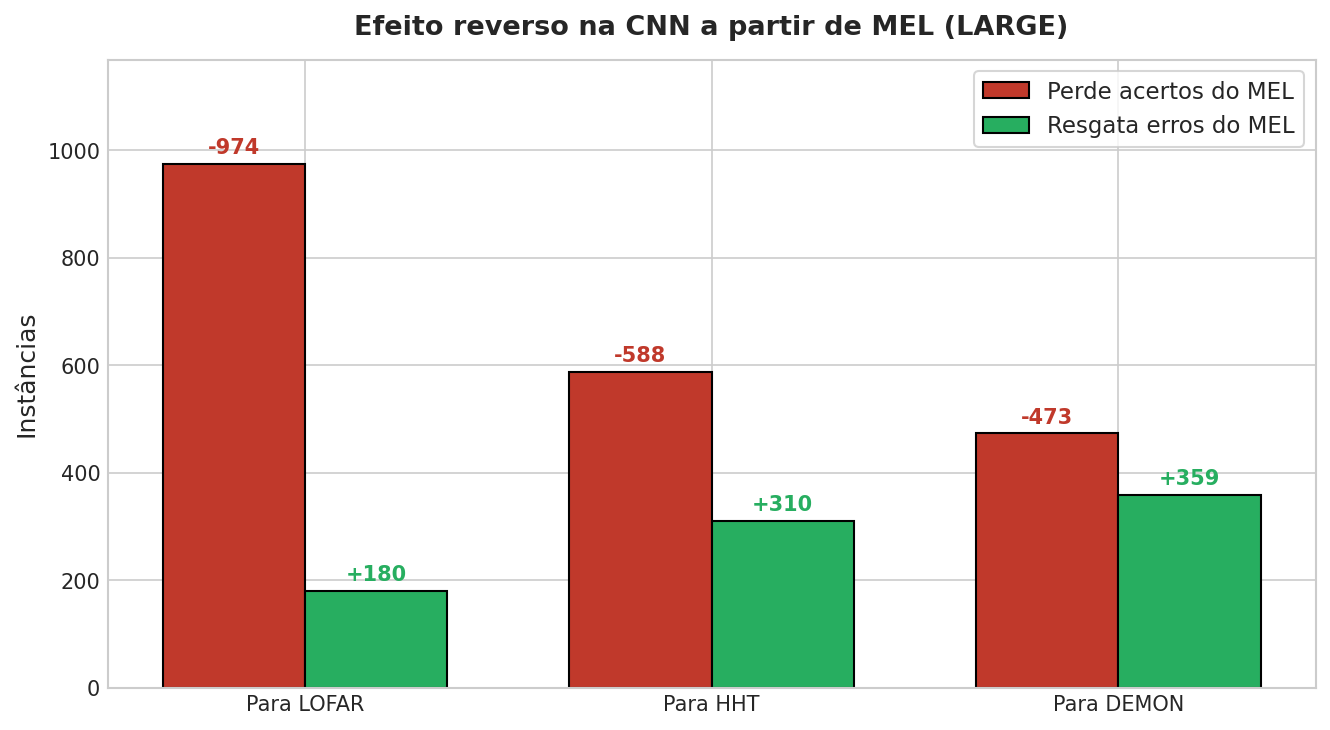

In [7]:
# 6. Visualização do efeito reverso a partir da melhor CNN isolada
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(df_reverse))
width = 0.35
lose_col = [c for c in df_reverse.columns if c.startswith('Perde_do_')][0]
resc_col = [c for c in df_reverse.columns if c.startswith('Resgata_Erros_')][0]
b1 = ax.bar(x - width/2, df_reverse[lose_col], width, label=f"Perde acertos do {A['base']}", color='#c0392b', edgecolor='black')
b2 = ax.bar(x + width/2, df_reverse[resc_col], width, label=f"Resgata erros do {A['base']}", color='#27ae60', edgecolor='black')
ax.set_title(f"Efeito reverso na CNN a partir de {A['base']} (LARGE)", fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(df_reverse['Destino_Troca'])
ax.set_ylabel('Instâncias')
ax.set_ylim(0, max(df_reverse[lose_col].max(), df_reverse[resc_col].max()) * 1.2)
for bars, sign, color in [(b1, '-', '#c0392b'), (b2, '+', '#27ae60')]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{sign}{int(h)}', xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold', color=color)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

## 7. Figura Consolidada

A figura `reports/analise_complementaridade_cnn_large_oraculo.png`, gerada por `scratch/generate_cnn_predictions_and_analysis.py`, **não é mais exibida aqui**. Ela usa a regra de desempate do script (menor índice de classe), e por isso os números não batem com os deste notebook (Seção 2.1); além disso, os títulos dela falam em "Áudios Únicos" quando os valores são instâncias de fold. Os quatro painéis da figura estão nas Seções 3–5 acima, recalculados.

## 8. Comparativo entre Famílias em `LARGE`: SVM vs. MLP vs. RF vs. CNN 2D

Experimentos: SVM — MEL m=4000, LOFAR m=6000, HHT/DEMON m=4000; MLP — `mlp`, `mlp_lofar`, `mlp_hht_h32-16_e30_4c`, `mlp_demon_h32-16_e30_4c`; RF — `rf_{mel5s,lofar5s,hht,demon}_n100_balanced_4c`; CNN — como acima. A lista completa está em `C.FAMILIES`.

| Família | Melhor isolado (recall) | Oráculo obs. / esperado indep. | Unanimidade 4/4 | Erro comum 0/4 | "≥2/4" (empates = acerto) | Voto real (recall) | SP global: voto vs. melhor isolado (F-test) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :--- |
| **SVM Nyström** (NB 13) | 76,31% (LOFAR) | 90,84% / 99,08% | 40,14% | 9,16% | 79,35% | 76,31% | 65,08 vs. 63,83 (LOFAR), p = 0,538 |
| **MLP** (NB 16) | 74,72% (LOFAR) | 89,25% / 99,12% | 44,44% | 10,75% | 78,50% | 75,84% | 66,01 vs. 66,24 (LOFAR), p = 0,485 |
| **Random Forest** (NB 19) | 75,79% (LOFAR) | 90,98% / 99,34% | 46,31% | 9,02% | 80,42% | 77,10% | 62,76 vs. 63,07 (LOFAR), p = 0,783 |
| **CNN 2D** (NB 22) | 64,58% (MEL) | 91,26% / 95,57% | 6,92% | 8,74% | 68,36% | 62,90% | 55,33 vs. 63,80 (MEL), p = 0,028 |

**Leitura:**
- Em nenhuma família o voto real das 4 entradas supera, com significância (F-test 5×2cv, p < 0,05), o melhor modelo isolado em SP global. Na CNN, o voto é **significativamente pior** (55,33% vs. 63,80%, p = 0,028), o que é coerente com 3 dos 4 votantes estarem colapsados.
- A unanimidade da CNN (6,92%) é bem menor que a das outras famílias (até 46,31%). Isso decorre do colapso das CNNs ad hoc, e não de uma "ortogonalidade" das representações.
- Em todas as famílias o oráculo observado fica abaixo do esperado sob independência (erros correlacionados).

In [8]:
# 8. Tabela comparativa recalculada (todas as famílias, classe LARGE)
fam_df, _ = C.family_table(CLASSE)
display(fam_df)

,SVM Nyström (NB 13),MLP (NB 16),Random Forest (NB 19),CNN 2D (NB 22)
Melhor modelo isolado (recall),76.31% (LOFAR),74.72% (LOFAR),75.79% (LOFAR),64.58% (MEL)
Oráculo observado (≥1/4),90.84% (1944),89.25% (1910),90.98% (1947),91.26% (1953)
Oráculo esperado c/ erros independentes,99.08%,99.12%,99.34%,95.57%
Unanimidade (4/4),40.14% (859),44.44% (951),46.31% (991),6.92% (148)
Erro comum (0/4),9.16% (196),10.75% (230),9.02% (193),8.74% (187)
Campeão de resgates exclusivos,DEMON (122),DEMON (131),DEMON (112),MEL (155)
≥2/4 (empates contam como acerto),79.35%,78.50%,80.42%,68.36%
Voto real (recall da classe),76.31%,75.84%,77.10%,62.90%
Voto real: SP global,65.08 ± 3.36,66.01 ± 1.79,62.76 ± 2.10,55.33 ± 3.07
Melhor SP isolado,63.83 ± 1.91 (LOFAR),66.24 ± 1.78 (LOFAR),63.07 ± 1.81 (LOFAR),63.80 ± 2.23 (MEL)
